# ComicVision AI - Milestone 03
## Data Audit and Exploratory Data Analysis

**Dataset:** 20-comic verified pilot catalog

### Learning objectives

1. Inspect the dataset structure.
2. Identify missing values and duplicates.
3. Explore publisher, era, and genre distributions.
4. Evaluate cover image quality.
5. Assess suitability for downstream ML tasks.



In [1]:
# Milestone 03 — Environment and imports
import pandas as pd

print("pandas version:", pd.__version__)
print("pandas imported successfully!")


pandas version: 3.1.1
pandas imported successfully!


In [2]:
from pathlib import Path

# Locate the project root from the notebook directory
project_root = Path.cwd().resolve()

if not (project_root / "data").exists():
    project_root = project_root.parent

# Locate the verified pilot catalog
catalog_path = project_root / "data" / "raw" / "metadata" / "comic_catalog_pilot.csv"

# Load the CSV into a pandas DataFrame
df = pd.read_csv(catalog_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Dataset loaded successfully!
Rows: 20
Columns: 12


In [3]:
#Preview the comic catalog
df.head(5)


,comic_id,title,issue_number,publisher,issue_date,publication_year,genre_tags,description,cover_image_path,metadata_source,verification_status,notes
0,CV0001,The New Teen Titans,25,DC Comics,1982-11,1982,NaN,NaN,data/raw/covers/CV0001_front.jpg,Physical front cover and interior indicia,verified,November 1982 cover date; 60-cent cover price;...
1,CV0002,Spider-Woman,32,Marvel Comics Group,1980-11,1980,NaN,NaN,data/raw/covers/CV0002_front.jpg,Physical front cover and interior indicia,verified,November 1980 issue date; Vol. 1; 50-cent cove...
2,CV0003,Wonder Woman,257,DC Comics Inc.,1979-07,1979,NaN,NaN,data/raw/covers/CV0003_front.jpg,Physical front cover and interior indicia,verified,July 1979 issue date; Vol. 38; 40-cent cover p...
3,CV0004,Power Man and Iron Fist,97,Marvel Comics Group,1983-09,1983,NaN,NaN,data/raw/covers/CV0004_front.jpg,Physical front cover and interior indicia,verified,September 1983 issue date; Vol. 1; 60-cent cov...
4,CV0005,Wolverine,90,Marvel Comics,1995-02,1995,NaN,NaN,data/raw/covers/CV0005_front.jpg,Physical front cover and interior indicia,verified,February 1995 cover date; $1.95 cover price; i...


In [4]:

#Inspect DataFrame structure and data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   comic_id             20 non-null     str    
 1   title                20 non-null     str    
 2   issue_number         20 non-null     int64  
 3   publisher            20 non-null     str    
 4   issue_date           18 non-null     str    
 5   publication_year     20 non-null     int64  
 6   genre_tags           0 non-null      float64
 7   description          0 non-null      float64
 8   cover_image_path     20 non-null     str    
 9   metadata_source      20 non-null     str    
 10  verification_status  20 non-null     str    
 11  notes                20 non-null     str    
dtypes: float64(2), int64(2), str(8)
memory usage: 2.0 KB


In [5]:
#Missing-value analysis
missing_counts = df.isna().sum()

print("Missing values by column:")
print(missing_counts)


Missing values by column:
comic_id                0
title                   0
issue_number            0
publisher               0
issue_date              2
publication_year        0
genre_tags             20
description            20
cover_image_path        0
metadata_source         0
verification_status     0
notes                   0
dtype: int64


In [6]:
#Calculate missing-value percentages
missing_percentages = (df.isna().sum() / len(df)) * 100

print("Missing-value percentages:")
print(missing_percentages.round(1))


Missing-value percentages:
comic_id                 0.0
title                    0.0
issue_number             0.0
publisher                0.0
issue_date              10.0
publication_year         0.0
genre_tags             100.0
description            100.0
cover_image_path         0.0
metadata_source          0.0
verification_status      0.0
notes                    0.0
dtype: float64


In [7]:
#Duplicate detection
duplicate_rows = df.duplicated().sum()

duplicate_ids = df["comic_id"].duplicated().sum()

print("Duplicate rows:", duplicate_rows)
print("Duplicate comic IDs:", duplicate_ids)


Duplicate rows: 0
Duplicate comic IDs: 0


In [8]:
#Publisher distribution analysis
publisher_counts = df["publisher"].value_counts()

print("Comics by publisher:")
print(publisher_counts)


Comics by publisher:
publisher
Marvel Comics Group                 10
DC Comics Inc.                       3
Western Publishing Company, Inc.     2
Dark Horse Comics, Inc.              2
DC Comics                            1
Marvel Comics                        1
Pied Piper Comics                    1
Name: count, dtype: int64


In [9]:
#Inspect unique publisher labels
unique_publishers = df["publisher"].unique()

print("Unique publisher labels:")
print(unique_publishers)

print("\nNumber of unique labels:", len(unique_publishers))


Unique publisher labels:
<StringArray>
[                       'DC Comics',              'Marvel Comics Group',
                   'DC Comics Inc.',                    'Marvel Comics',
 'Western Publishing Company, Inc.',                'Pied Piper Comics',
          'Dark Horse Comics, Inc.']
Length: 7, dtype: str

Number of unique labels: 7


In [10]:
#Standardize publisher groups
publisher_mapping = {
    "Marvel Comics Group": "Marvel",
    "Marvel Comics": "Marvel",
    "DC Comics Inc.": "DC",
    "DC Comics": "DC",
    "Western Publishing Company, Inc.": "Western Publishing",
    "Dark Horse Comics, Inc.": "Dark Horse",
    "Pied Piper Comics": "Pied Piper"
}

# Create a new column without changing the original
df["publisher_group"] = df["publisher"].map(publisher_mapping)

print("Standardized publisher distribution:")
print(df["publisher_group"].value_counts())


Standardized publisher distribution:
publisher_group
Marvel                11
DC                     4
Western Publishing     2
Dark Horse             2
Pied Piper             1
Name: count, dtype: int64


In [11]:
#Publication-year distribution
print("Oldest publication year:", df["publication_year"].min())
print("Newest publication year:", df["publication_year"].max())

print("\nComics by publication year:")
print(df["publication_year"].value_counts().sort_index())


Oldest publication year: 1978
Newest publication year: 1997

Comics by publication year:
publication_year
1978    2
1979    2
1980    3
1982    1
1983    4
1984    3
1986    1
1987    1
1995    2
1997    1
Name: count, dtype: int64


In [12]:
#Create publication-decade feature
df["publication_decade"] = (
    df["publication_year"] // 10 * 10
)

print("Comics by publication decade:")
print(df["publication_decade"].value_counts().sort_index())


Comics by publication decade:
publication_decade
1970     4
1980    13
1990     3
Name: count, dtype: int64


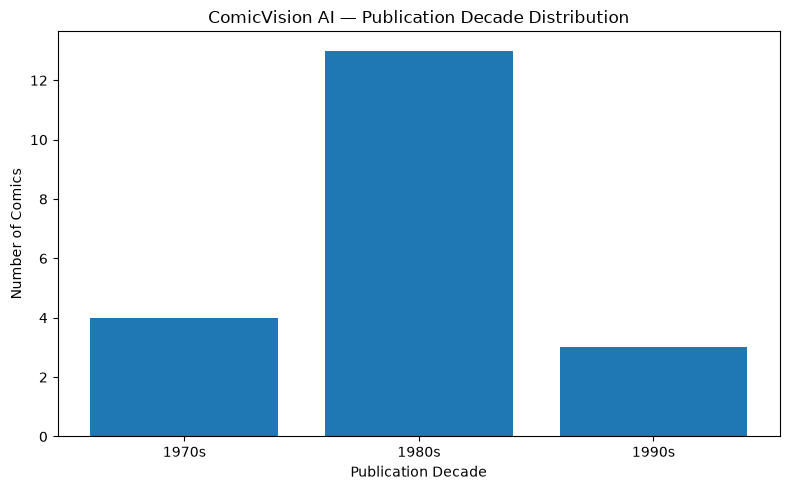

In [13]:
#Visualize publication-decade distribution
import matplotlib.pyplot as plt

decade_counts = df["publication_decade"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    decade_counts.index.astype(str) + "s",
    decade_counts.values
)

plt.title("ComicVision AI — Publication Decade Distribution")
plt.xlabel("Publication Decade")
plt.ylabel("Number of Comics")

plt.tight_layout()
plt.show()


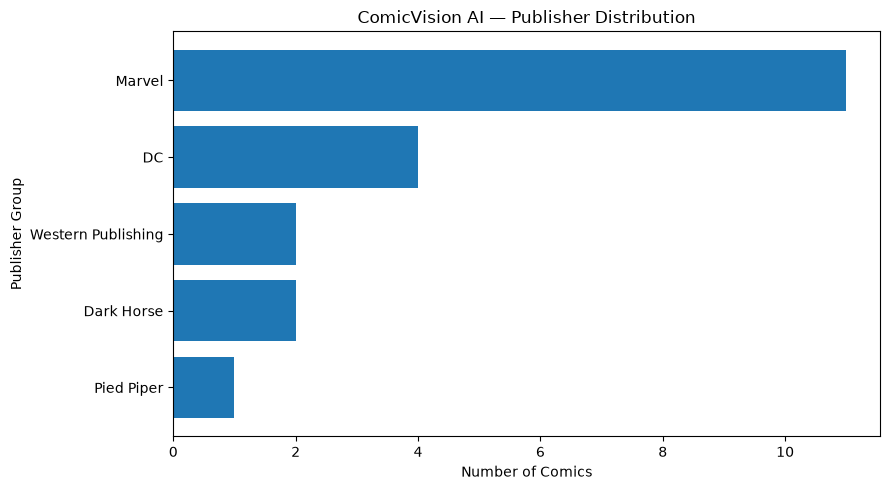

In [14]:
#Visualize standardized publisher distribution
publisher_counts = df["publisher_group"].value_counts()

plt.figure(figsize=(9, 5))

plt.barh(
    publisher_counts.index,
    publisher_counts.values
)

plt.title("ComicVision AI — Publisher Distribution")
plt.xlabel("Number of Comics")
plt.ylabel("Publisher Group")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [15]:
#Inspect the dimensions of our first comic cover
from PIL import Image

cover_path = project_root / df.loc[0, "cover_image_path"]

with Image.open(cover_path) as img:
    print("Comic ID:", df.loc[0, "comic_id"])
    print("Image format:", img.format)
    print("Image width:", img.width)
    print("Image height:", img.height)
    print("Color mode:", img.mode)


Comic ID: CV0001
Image format: JPEG
Image width: 3209
Image height: 4641
Color mode: RGB


In [16]:
#Audit image dimensions and color modes
image_records = []

for _, comic in df.iterrows():
    image_path = project_root / comic["cover_image_path"]

    with Image.open(image_path) as img:
        image_records.append({
            "comic_id": comic["comic_id"],
            "width": img.width,
            "height": img.height,
            "format": img.format,
            "mode": img.mode
        })

image_df = pd.DataFrame(image_records)

print("Images audited:", len(image_df))
print("\nImage dimensions and properties:")
print(image_df.to_string(index=False))


Images audited: 20

Image dimensions and properties:
comic_id  width  height format mode
  CV0001   3209    4641   JPEG  RGB
  CV0002   2868    4080   JPEG  RGB
  CV0003   2739    4045   JPEG  RGB
  CV0004   2748    4045   JPEG  RGB
  CV0005   2657    3952   JPEG  RGB
  CV0006   2760    4010   JPEG  RGB
  CV0007   2653    3903   JPEG  RGB
  CV0008   2689    3971   JPEG  RGB
  CV0009   2639    3961   JPEG  RGB
  CV0010   2625    3907   JPEG  RGB
  CV0011   2707    3940   JPEG  RGB
  CV0012   2658    3994   JPEG  RGB
  CV0013   2693    3895   JPEG  RGB
  CV0014   2679    3911   JPEG  RGB
  CV0015   2608    3905   JPEG  RGB
  CV0016   2643    3892   JPEG  RGB
  CV0017   2691    3828   JPEG  RGB
  CV0018   2578    3867   JPEG  RGB
  CV0019   2607    3833   JPEG  RGB
  CV0020   2549    3865   JPEG  RGB


In [17]:
#Analyze image resolution and aspect ratios
image_df["megapixels"] = (
    image_df["width"] * image_df["height"] / 1_000_000
)

image_df["aspect_ratio"] = (
    image_df["width"] / image_df["height"]
)

print("Image quality statistics:")
print(
    image_df[
        ["width", "height", "megapixels", "aspect_ratio"]
    ].describe().round(3)
)


Image quality statistics:
        width    height  megapixels  aspect_ratio
count    20.0    20.000      20.000        20.000
mean   2700.0  3972.250      10.747         0.680
std     139.3   172.507       1.073         0.012
min    2549.0  3828.000       9.852         0.660
25%    2635.5  3894.250      10.279         0.671
50%    2668.5  3925.500      10.483         0.679
75%    2715.0  3998.000      10.775         0.687
max    3209.0  4641.000      14.893         0.703


In [18]:
#Detect image-resolution outliers using IQR
q1 = image_df["megapixels"].quantile(0.25)
q3 = image_df["megapixels"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = image_df[
    (image_df["megapixels"] < lower_bound) |
    (image_df["megapixels"] > upper_bound)
]

print("Lower bound:", round(lower_bound, 3))
print("Upper bound:", round(upper_bound, 3))

print("\nPotential resolution outliers:")
print(outliers[["comic_id", "megapixels"]].to_string(index=False))


Lower bound: 9.534
Upper bound: 11.52

Potential resolution outliers:
comic_id  megapixels
  CV0001   14.892969
  CV0002   11.701440


In [19]:
# Detect aspect-ratio outliers using IQR
q1_ratio = image_df["aspect_ratio"].quantile(0.25)
q3_ratio = image_df["aspect_ratio"].quantile(0.75)

iqr_ratio = q3_ratio - q1_ratio

lower_ratio = q1_ratio - 1.5 * iqr_ratio
upper_ratio = q3_ratio + 1.5 * iqr_ratio

ratio_outliers = image_df[
    (image_df["aspect_ratio"] < lower_ratio) |
    (image_df["aspect_ratio"] > upper_ratio)
]

print("Lower aspect-ratio bound:", round(lower_ratio, 3))
print("Upper aspect-ratio bound:", round(upper_ratio, 3))

print("\nPotential aspect-ratio outliers:")

if ratio_outliers.empty:
    print("None detected")
else:
    print(
        ratio_outliers[
            ["comic_id", "aspect_ratio"]
        ].to_string(index=False)
    )


Lower aspect-ratio bound: 0.646
Upper aspect-ratio bound: 0.712

Potential aspect-ratio outliers:
None detected


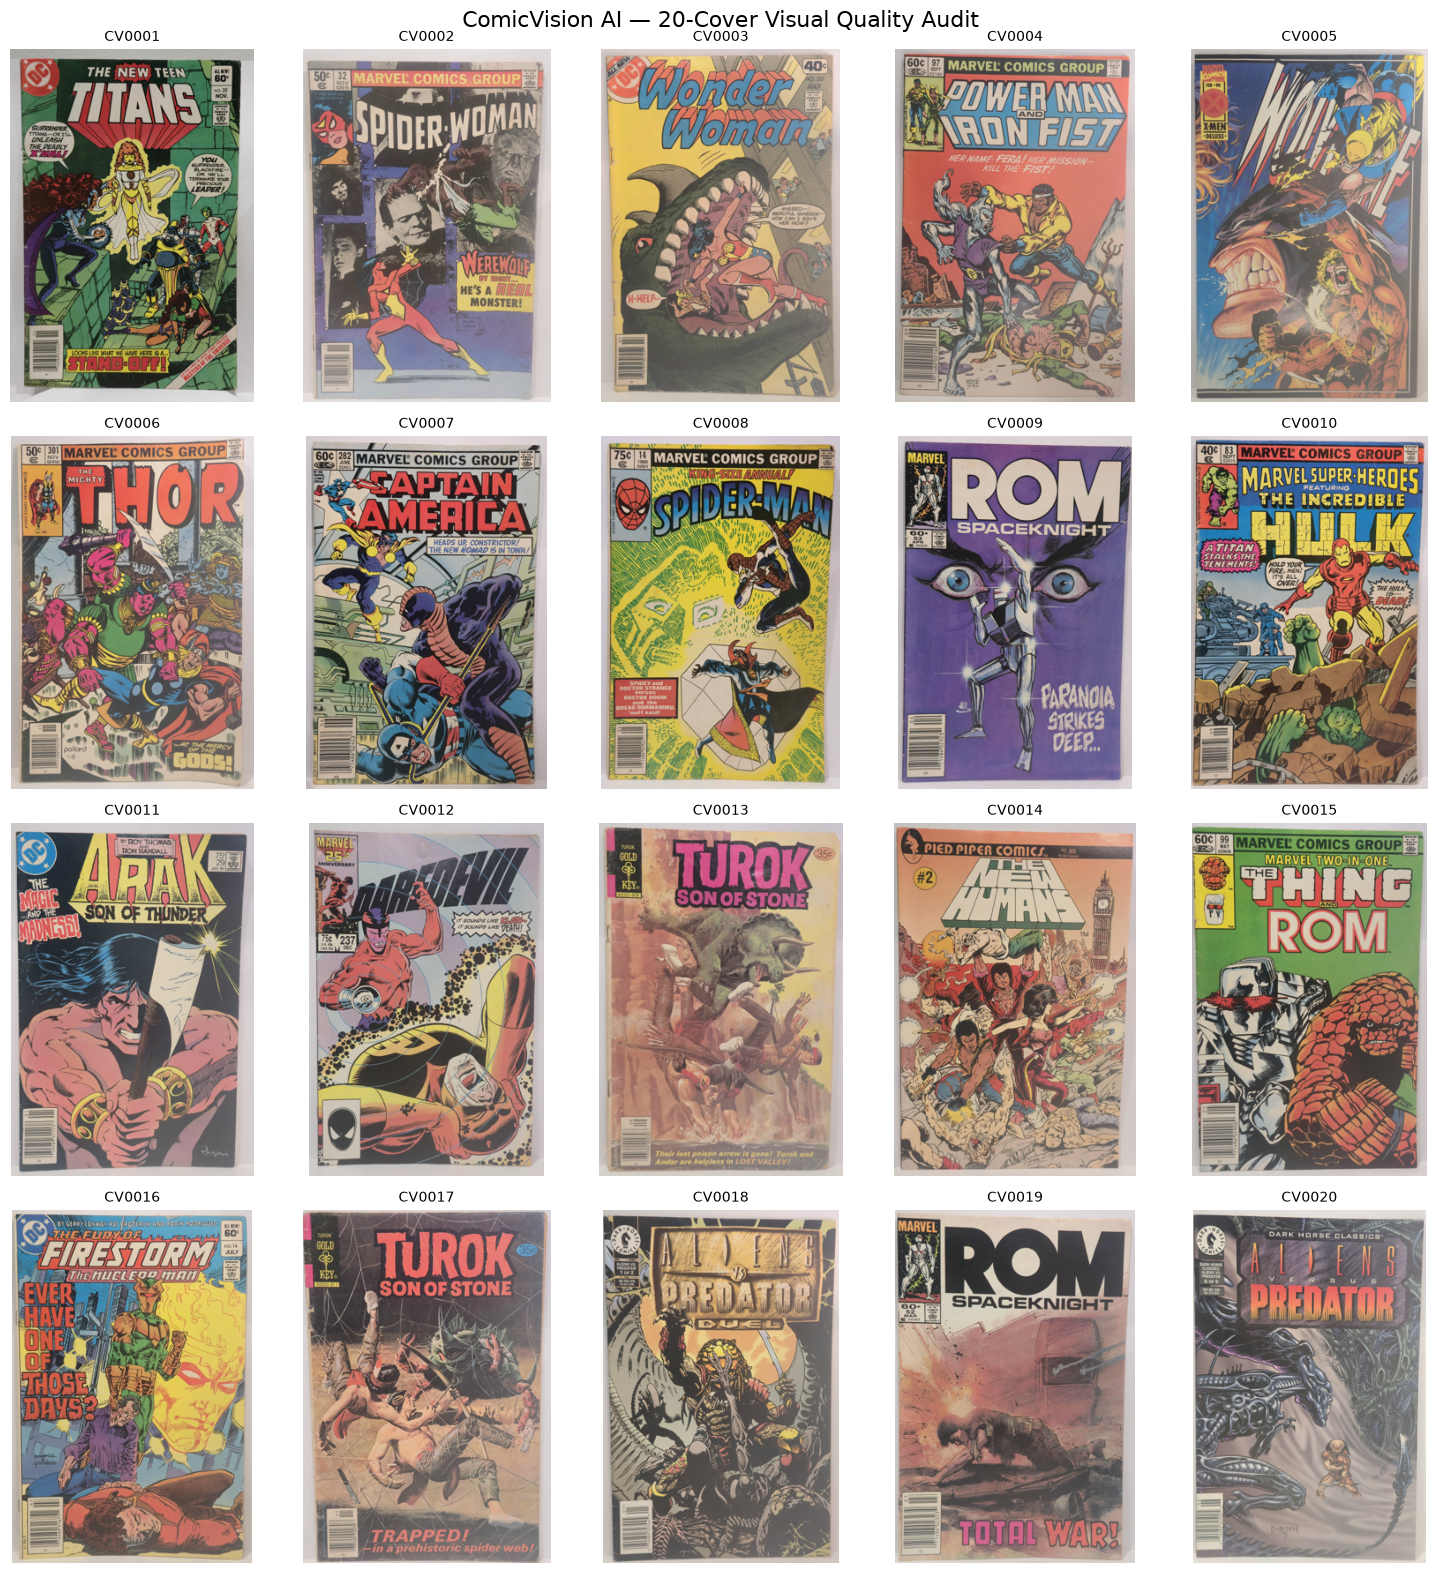

In [20]:
#Display all 20 comic covers for visual inspection
fig, axes = plt.subplots(4, 5, figsize=(15, 16))

for ax, (_, comic) in zip(axes.flat, df.iterrows()):
    image_path = project_root / comic["cover_image_path"]

    with Image.open(image_path) as img:
        preview = img.copy()
        preview.thumbnail((300, 400))

    ax.imshow(preview)
    ax.set_title(comic["comic_id"], fontsize=10)
    ax.axis("off")

plt.suptitle(
    "ComicVision AI — 20-Cover Visual Quality Audit",
    fontsize=16
)

plt.tight_layout()
plt.show()


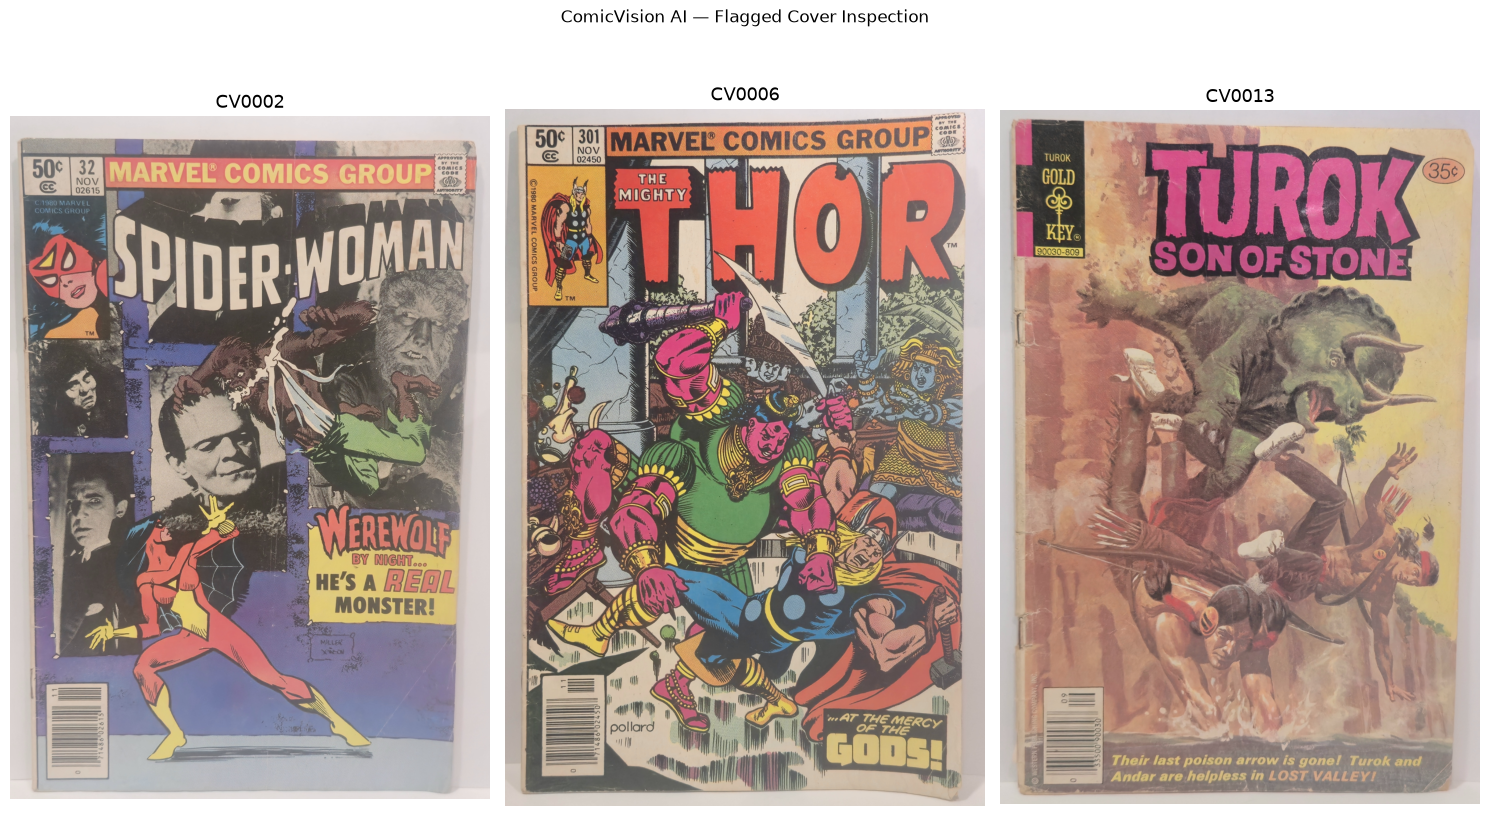

In [21]:
#Inspect flagged covers at larger preview size
flagged_ids = ["CV0002", "CV0006", "CV0013"]

fig, axes = plt.subplots(1, 3, figsize=(15, 9))

for ax, comic_id in zip(axes, flagged_ids):
    comic = df.loc[df["comic_id"] == comic_id].iloc[0]
    image_path = project_root / comic["cover_image_path"]

    with Image.open(image_path) as img:
        preview = img.copy()
        preview.thumbnail((900, 1200))

    ax.imshow(preview)
    ax.set_title(comic_id, fontsize=13)
    ax.axis("off")

plt.suptitle("ComicVision AI — Flagged Cover Inspection")
plt.tight_layout()
plt.show()


In [22]:
#Record preliminary visual-quality findings
review_notes = {
    "CV0002": "Possible reflections and reduced contrast",
    "CV0006": "Possible glare near lower cover",
    "CV0013": "Possible fading or reduced contrast"
}

image_df["visual_review_status"] = "preliminary_pass"

image_df.loc[
    image_df["comic_id"].isin(review_notes),
    "visual_review_status"
] = "review_recommended"

image_df["visual_review_notes"] = (
    image_df["comic_id"].map(review_notes).fillna("")
)

print("Visual review status:")
print(image_df["visual_review_status"].value_counts())

print("\nFlagged covers:")
print(
    image_df.loc[
        image_df["visual_review_status"] == "review_recommended",
        ["comic_id", "visual_review_notes"]
    ].to_string(index=False)
)


Visual review status:
visual_review_status
preliminary_pass      17
review_recommended     3
Name: count, dtype: int64

Flagged covers:
comic_id                       visual_review_notes
  CV0002 Possible reflections and reduced contrast
  CV0006           Possible glare near lower cover
  CV0013       Possible fading or reduced contrast


In [23]:
#Generate dataset suitability metrics
suitability_metrics = {
    "total_comics": len(df),
    "unique_publishers": df["publisher_group"].nunique(),
    "publication_decades": df["publication_decade"].nunique(),
    "genre_labels_available": df["genre_tags"].notna().sum(),
    "descriptions_available": df["description"].notna().sum(),
    "cover_images_audited": len(image_df),
    "images_requiring_review": (
        image_df["visual_review_status"] == "review_recommended"
    ).sum()
}

print("ComicVision AI — Dataset Suitability Metrics")

for metric, value in suitability_metrics.items():
    print(f"{metric}: {value}")


ComicVision AI — Dataset Suitability Metrics
total_comics: 20
unique_publishers: 5
publication_decades: 3
genre_labels_available: 0
descriptions_available: 0
cover_images_audited: 20
images_requiring_review: 3


In [24]:
#Export image-quality audit results
report_path = (
    project_root
    / "reports"
    / "milestone_03_image_quality_audit.csv"
)

report_path.parent.mkdir(parents=True, exist_ok=True)

image_df.to_csv(report_path, index=False)

print("Image audit saved successfully!")
print("File:", report_path.relative_to(project_root))
print("Records exported:", len(image_df))


Image audit saved successfully!
File: reports\milestone_03_image_quality_audit.csv
Records exported: 20


In [25]:
#Verify exported image-quality audit
saved_audit = pd.read_csv(report_path)

assert len(saved_audit) == 20, "Incorrect record count"
assert saved_audit["comic_id"].is_unique, "Duplicate comic IDs"
assert set(saved_audit["comic_id"]) == set(image_df["comic_id"]), "Comic IDs do not match"
assert saved_audit["visual_review_status"].value_counts().to_dict() == {
    "preliminary_pass": 17,
    "review_recommended": 3
}, "Visual review counts do not match"

print("CSV round-trip validation: PASS")
print("Records verified:", len(saved_audit))
print("Unique comic IDs:", saved_audit["comic_id"].nunique())
print("Review flags:", (
    saved_audit["visual_review_status"] == "review_recommended"
).sum())


CSV round-trip validation: PASS
Records verified: 20
Unique comic IDs: 20
Review flags: 3
